In [4]:
import pandas as pd
import numpy as np
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)

from sklearn.ensemble import (RandomForestRegressor,GradientBoostingRegressor)

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder,StandardScaler

from sklearn.compose import ColumnTransformer

from sklearn.model_selection import (train_test_split,GridSearchCV,KFold,cross_validate)

from sklearn.linear_model import LinearRegression,Ridge,Lasso

from sklearn.tree import DecisionTreeRegressor

from sklearn.impute import  SimpleImputer

In [5]:
df=pd.read_csv(r"C:\Users\Shehan\OneDrive\Desktop\PROJECT_\data\cleaned_data.csv")
df.head()

,Month,Province,District,Household_Type,Household_Size,House_Area_m2,Bedrooms,AC_Units,Fans,Refrigerators,...,Other_High_Power_Appliances,Avg_Daily_AC_Hours,Avg_Daily_Fan_Hours,Avg_Daily_TV_Hours,Avg_Daily_Cooking_Hours,Solar_PV,Solar_Capacity_kW,Avg_Temperature_C,Previous_Month_kWh,Target_Monthly_kWh
0,January,Eastern,Ampara,Single_Family,4,69.1,1,1.0,4,1,...,3,5.1,4.7,3.5,3.3,No,0.0,30.3,369.7,350.8
1,January,Eastern,Ampara,Apartment,6,54.1,2,0.0,7,1,...,0,0.0,7.9,6.3,3.0,No,0.0,30.3,290.9,281.8
2,January,North Central,Anuradhapura,Single_Family,2,196.9,5,0.0,3,1,...,1,0.0,10.7,4.1,3.9,No,0.0,25.4,241.6,277.9
3,January,North Central,Anuradhapura,Single_Family,4,122.8,3,0.0,4,2,...,3,0.0,9.2,5.7,3.7,No,0.0,27.4,270.7,286.7
4,January,Uva,Badulla,Single_Family,5,93.9,2,0.0,5,1,...,2,0.0,4.7,2.7,1.4,No,0.0,29.6,307.3,303.0


In [6]:
df.shape

(1000, 24)

In [7]:
x = df.drop(columns=["Target_Monthly_kWh"])
y = df["Target_Monthly_kWh"]

In [8]:
categorical_features=x.select_dtypes(include=["object"]).columns.to_list()
numerical_features=x.select_dtypes(exclude=["object"]).columns.to_list()

C:\Users\Shehan\AppData\Local\Temp\ipykernel_19528\940615185.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features=x.select_dtypes(include=["object"]).columns.to_list()


In [9]:
print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)


Categorical features:
['Month', 'Province', 'District', 'Household_Type', 'Solar_PV']

Numerical features:
['Household_Size', 'House_Area_m2', 'Bedrooms', 'AC_Units', 'Fans', 'Refrigerators', 'TVs', 'Washing_Machines', 'Water_Heaters', 'Computers', 'Other_High_Power_Appliances', 'Avg_Daily_AC_Hours', 'Avg_Daily_Fan_Hours', 'Avg_Daily_TV_Hours', 'Avg_Daily_Cooking_Hours', 'Solar_Capacity_kW', 'Avg_Temperature_C', 'Previous_Month_kWh']


In [10]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

In [11]:
print("X_train:", x_train.shape)
print("X_test :", x_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (800, 23)
X_test : (200, 23)
y_train: (800,)
y_test : (200,)


In [12]:
numeric_transform=Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="median")),
        ("scaler",StandardScaler())
    ]
)

In [13]:
categorical_transform=Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="most_frequent")),
        ("onehot",OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [14]:
preprocessor=ColumnTransformer(
    transformers=[
        ("num",numeric_transform,numerical_features),
        ("cat",categorical_transform,categorical_features)
    ]
)

In [15]:
linear_pipeline=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("model",LinearRegression())
    ]
)

In [16]:
tree_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(random_state=42))
    ]
)

In [17]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            random_state=42,
            n_estimators=200
        ))
    ]
)

In [18]:
gb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", GradientBoostingRegressor(
            random_state=42
        ))
    ]
)

In [19]:
models = {
    "Linear Regression": linear_pipeline,
    "Decision Tree": tree_pipeline,
    "Random Forest": rf_pipeline,
    "Gradient Boosting": gb_pipeline
}

In [20]:
cv=KFold(n_splits=5,shuffle=True,random_state=42)

In [21]:
scoring={
    "MAE":"neg_mean_absolute_error",
    "RMSE":"neg_root_mean_squared_error",
    "R2":"r2"
}

In [22]:
cv_result=[]

for name,model in models.items():

    scores=cross_validate(
        model,
        x_train,y_train,cv=cv,scoring=scoring,n_jobs=-1
    )

    mae=-scores["test_MAE"]
    rmse=-scores["test_RMSE"]
    r2=scores["test_R2"]

    cv_result.append({
        "model":name,
        "mean MAE":mae.mean(),
        "std MAE":mae.std(),
        "mean RMSE":rmse.mean(),
        "std RMSE":rmse.std(),
        "mean R2":r2.mean(),
        "std R2":r2.std()
    })

In [23]:
cv_result_df=pd.DataFrame(cv_result)
cv_result_df

,model,mean MAE,std MAE,mean RMSE,std RMSE,mean R2,std R2
0,Linear Regression,23.974182,1.237889,30.188727,1.613691,0.876878,0.019457
1,Decision Tree,42.415875,2.311626,53.028672,2.402949,0.620688,0.057193
2,Random Forest,30.148410,0.547762,38.060795,0.527836,0.805274,0.020073
3,Gradient Boosting,28.660735,0.738084,36.311564,1.033043,0.822549,0.020986


In [24]:
cv_result_df.sort_values(by="mean MAE")

,model,mean MAE,std MAE,mean RMSE,std RMSE,mean R2,std R2
0,Linear Regression,23.974182,1.237889,30.188727,1.613691,0.876878,0.019457
3,Gradient Boosting,28.660735,0.738084,36.311564,1.033043,0.822549,0.020986
2,Random Forest,30.148410,0.547762,38.060795,0.527836,0.805274,0.020073
1,Decision Tree,42.415875,2.311626,53.028672,2.402949,0.620688,0.057193


In [25]:
cv_result_df.sort_values(by="mean R2",ascending=False)

,model,mean MAE,std MAE,mean RMSE,std RMSE,mean R2,std R2
0,Linear Regression,23.974182,1.237889,30.188727,1.613691,0.876878,0.019457
3,Gradient Boosting,28.660735,0.738084,36.311564,1.033043,0.822549,0.020986
2,Random Forest,30.148410,0.547762,38.060795,0.527836,0.805274,0.020073
1,Decision Tree,42.415875,2.311626,53.028672,2.402949,0.620688,0.057193


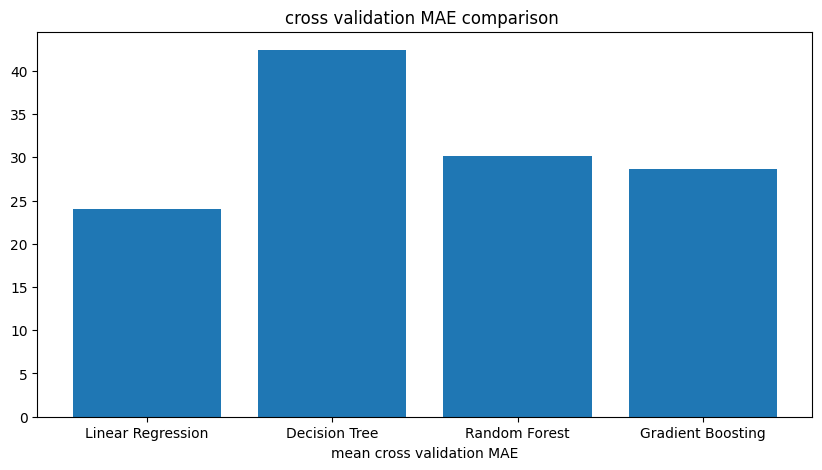

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.bar(cv_result_df["model"],cv_result_df["mean MAE"])

plt.xlabel("mean cross validation MAE")
plt.title("cross validation MAE comparison ")
plt.xticks(rotation =0)

plt.show()

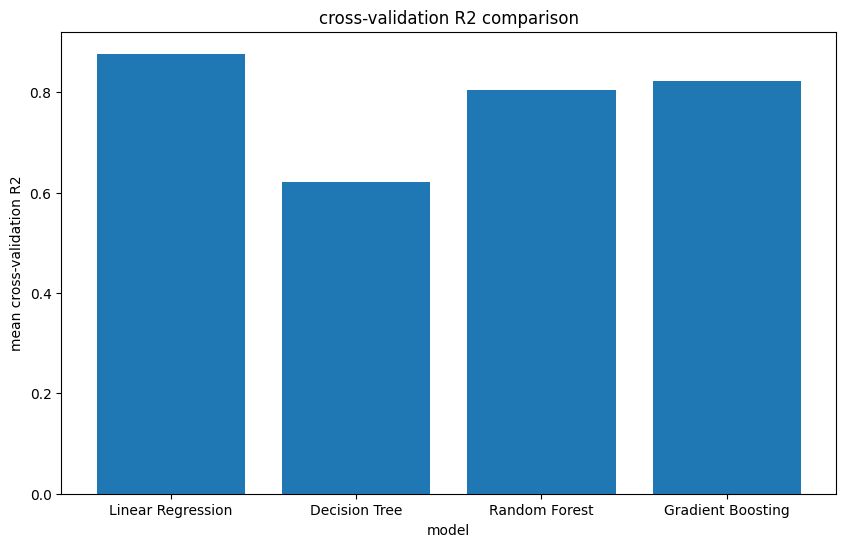

In [27]:
plt.figure(figsize=(10, 6))

plt.bar(
    cv_result_df["model"],
    cv_result_df["mean R2"]
)

plt.xlabel("model")
plt.ylabel("mean cross-validation R2")
plt.title("cross-validation R2 comparison")
plt.xticks(rotation=0)

plt.show()

## 11. Ridge Regression

Since Linear Regression produced the best baseline performance,
we will test Ridge Regression to determine whether regularization
can improve generalization.


In [28]:
ridge_pipeline=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("model",Ridge())
    ]
)

In [29]:
ridge_para={"model__alpha":[0.01,0.1,1,10,100,1000]}

In [30]:
ridge_grid=GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_para,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    return_train_score=True
)
ridge_grid.fit(x_train,y_train)
print("best parameters:",ridge_grid.best_params_)
print("best cv MAE:",-ridge_grid.best_score_)


best parameters: {'model__alpha': 10}
best cv MAE: 23.77689669038083


In [31]:
ridge_best=ridge_grid.best_estimator_
ridge_pred=ridge_best.predict(x_test)

In [32]:
ridge_mae = mean_absolute_error(y_test,ridge_pred)

ridge_rmse = np.sqrt(mean_squared_error(y_test,ridge_pred))

ridge_r2 = r2_score(y_test,ridge_pred)

In [33]:
print("Ridge Regression")
print("-------------------------")
print("MAE :", ridge_mae)
print("RMSE:", ridge_rmse)
print("R²  :", ridge_r2)

Ridge Regression
-------------------------
MAE : 24.25520532210906
RMSE: 29.677975480224816
R²  : 0.8847612984584183


In [34]:
rf_pipeline=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("model",RandomForestRegressor(random_state=42))
    ]
)

In [35]:
rf_para={
    "model__n_estimators":[100,200,300],
    "model__max_depth":[None,10,20],
    "model__min_samples_split":[2,5],
    "model__min_samples_leaf":[1,2]}

In [36]:
rf_grid=GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_para,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    return_train_score=True 
)

In [37]:
rf_grid.fit(x_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,`

In [38]:
print("Best parameters:", rf_grid.best_params_)
print("Best CV MAE:", -rf_grid.best_score_)

Best parameters: {'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 300}
Best CV MAE: 29.990425421337925


In [39]:
rf_best = rf_grid.best_estimator_

rf_pred = rf_best.predict(x_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Tuned Random Forest")
print("-------------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R²  :", rf_r2)

Tuned Random Forest
-------------------------
MAE : 29.688026629717506
RMSE: 37.191365343677035
R²  : 0.8190268869072123


In [40]:
gb_pipeline=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("model",GradientBoostingRegressor(random_state=42))
    ]
)

In [41]:
gb_para={
    "model__n_estimators":[100,200,300],
    "model__learning_rate":[0.03,0.05,0.1],
    "model__max_depth":[2,3,4],
    "model__min_samples_split":[2,5]
}

In [42]:
gb_grid=GridSearchCV(
    estimator=gb_pipeline,
    param_grid=gb_para,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    return_train_score=True
)

In [43]:
gb_grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__learning_rate': [0.03, 0.05, ...], 'model__max_depth': [2, 3, ...], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_

In [44]:
print("Best parameters:", gb_grid.best_params_)
print("Best CV MAE:", -gb_grid.best_score_)

Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__min_samples_split': 5, 'model__n_estimators': 300}
Best CV MAE: 28.179973161870883


In [45]:
gb_best = gb_grid.best_estimator_

gb_pred = gb_best.predict(x_test)

gb_mae = mean_absolute_error(y_test, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred))
gb_r2 = r2_score(y_test, gb_pred)

print("Tuned Gradient Boosting")
print("-------------------------")
print("MAE :", gb_mae)
print("RMSE:", gb_rmse)
print("R²  :", gb_r2)

Tuned Gradient Boosting
-------------------------
MAE : 27.987945909593883
RMSE: 35.48457385303435
R²  : 0.835256229748022


In [46]:
tuned_results = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "CV_MAE": [
        -ridge_grid.best_score_,
        -rf_grid.best_score_,
        -gb_grid.best_score_
    ],
    "Test_MAE": [
        ridge_mae,
        rf_mae,
        gb_mae
    ],
    "Test_RMSE": [
        ridge_rmse,
        rf_rmse,
        gb_rmse
    ],
    "Test_R2": [
        ridge_r2,
        rf_r2,
        gb_r2
    ]
})

tuned_results

,Model,CV_MAE,Test_MAE,Test_RMSE,Test_R2
0,Ridge Regression,23.776897,24.255205,29.677975,0.884761
1,Random Forest,29.990425,29.688027,37.191365,0.819027
2,Gradient Boosting,28.179973,27.987946,35.484574,0.835256


In [47]:
tuned_results.round(3)

,Model,CV_MAE,Test_MAE,Test_RMSE,Test_R2
0,Ridge Regression,23.777,24.255,29.678,0.885
1,Random Forest,29.990,29.688,37.191,0.819
2,Gradient Boosting,28.180,27.988,35.485,0.835


In [48]:
tuned_results.sort_values(by="Test_MAE",ascending=True)

,Model,CV_MAE,Test_MAE,Test_RMSE,Test_R2
0,Ridge Regression,23.776897,24.255205,29.677975,0.884761
2,Gradient Boosting,28.179973,27.987946,35.484574,0.835256
1,Random Forest,29.990425,29.688027,37.191365,0.819027


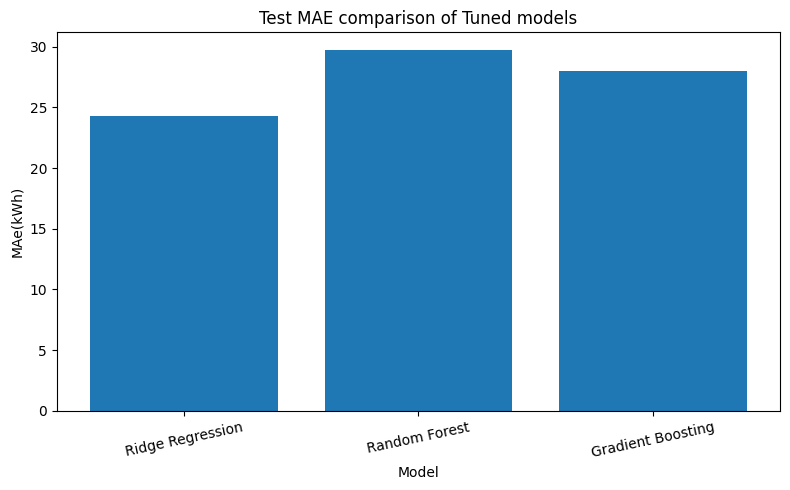

In [49]:
plt.figure(figsize=(8,5))

plt.bar(tuned_results["Model"],tuned_results["Test_MAE"])

plt.ylabel("MAe(kWh)")
plt.xlabel("Model")
plt.title("Test MAE comparison of Tuned models")

plt.xticks(rotation=12)
plt.tight_layout()
plt.show()

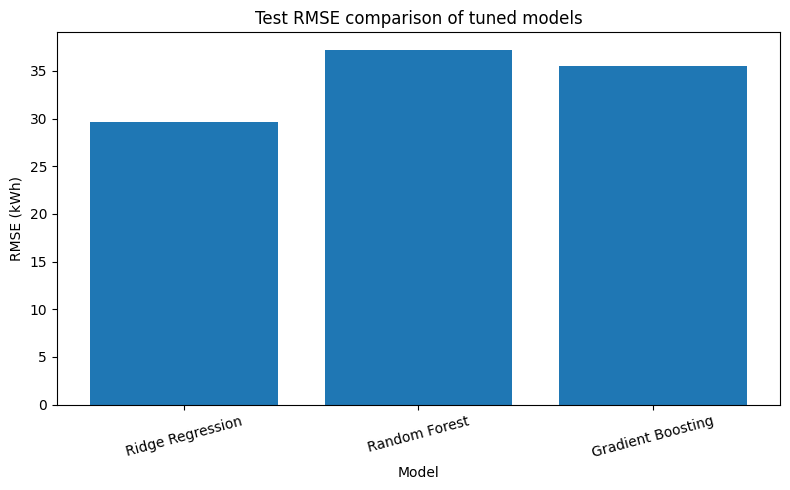

In [50]:
plt.figure(figsize=(8, 5))

plt.bar(
    tuned_results["Model"],
    tuned_results["Test_RMSE"]
)

plt.ylabel("RMSE (kWh)")
plt.xlabel("Model")
plt.title("Test RMSE comparison of tuned models")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


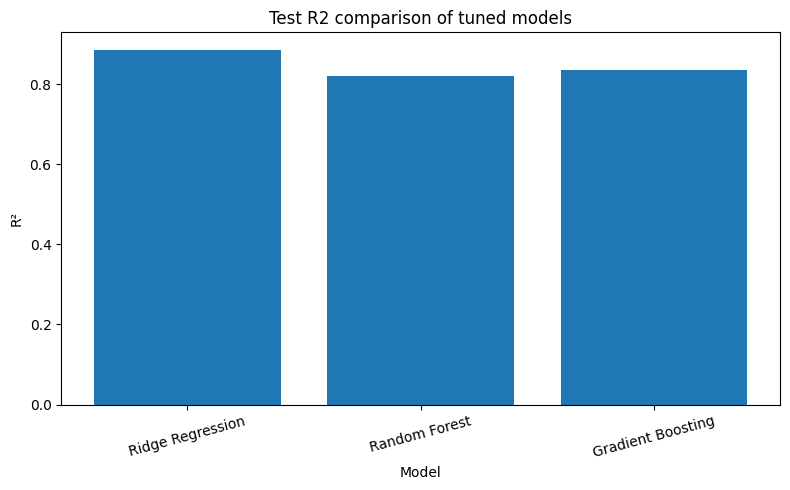

In [51]:
plt.figure(figsize=(8, 5))

plt.bar(
    tuned_results["Model"],
    tuned_results["Test_R2"]
)

plt.ylabel("R²")
plt.xlabel("Model")
plt.title("Test R2 comparison of tuned models")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [52]:
best_model = tuned_results.loc[
    tuned_results["Test_MAE"].idxmin()
]

print("Best Model:")
print(best_model)

Best Model:
Model        Ridge Regression
CV_MAE              23.776897
Test_MAE            24.255205
Test_RMSE           29.677975
Test_R2              0.884761
Name: 0, dtype: object


## Final Model Selection

Three tuned regression models were compared using 5-fold cross-validation
and an independent test set: Ridge Regression, Random Forest, and Gradient
Boosting.

Ridge Regression achieved the lowest cross-validation MAE and the lowest
test MAE and RMSE. It also achieved the highest test R².

Therefore, Ridge Regression with alpha = 10 was selected as the final model
for monthly household electricity consumption prediction.


# 7. Save Final Model

In [53]:
import joblib

In [54]:
final_model = ridge_grid.best_estimator_

print(final_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Household_Size',
                                                   'House_Area_m2', 'Bedrooms',
                                                   'AC_Units', 'Fans',
                                                   'Refrigerators', 'TVs',
                                                   'Washing_Machines',
                                                   'Water_Heaters', 'Computers',
                                                   'Other_High_Power_Appliances',
                                    

In [55]:
joblib.dump(final_model,"electricity_model.pkl")

['electricity_model.pkl']

In [56]:
loaded_model = joblib.load(
    "electricity_model.pkl"
)

print("Model loaded successfully.")

Model loaded successfully.


In [57]:
sample=loaded_model.predict(x_test.iloc[:5])
print(sample)

[283.49519102 354.23723148 423.72491523 317.9822804  344.37466185]


In [58]:
comparison = pd.DataFrame({
    "Actual_kWh": y_test.iloc[:5].values,
    "Predicted_kWh": sample
})

comparison

,Actual_kWh,Predicted_kWh
0,254.4,283.495191
1,377.4,354.237231
2,376.8,423.724915
3,294.9,317.982280
4,359.5,344.374662


## Final Model

After comparing the tuned models, Ridge Regression with alpha = 10
was selected as the final model.

The final pipeline was saved using Joblib as:

`models/electricity_model.pkl`

The saved pipeline includes the preprocessing steps and the Ridge
Regression model, allowing new household data to be directly passed
to the model for prediction.